# 10 - Figures for the README

Every chart in the README is made here, from the same data and code as the other notebooks, so they can be regenerated. Nothing in this notebook changes a result. The McLaren section is descriptive and uses the 2025 season after the final test was already done.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold

from f1lab.backtest import driver_races, replay
from f1lab.conformal import CQR, ConstantWidth, coverage
from f1lab.evaluate import lap_time_results, simulator_results
from f1lab.features import drying_races, mae, prepare, split, wet_races
from f1lab.models import gbm_features, make_gbm
from f1lab.race_costs import pit_stops
from f1lab.safety_car import hazard_table, lap_status
from f1lab.simulate import GBM_LEAVES, GBM_TREES, build_simulator

PAPAYA, GREY, BLUE, RED = "#FF8000", "#9aa0a6", "#3b6fb6", "#c0392b"
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
OUT = Path("../reports"); OUT.mkdir(exist_ok=True)
def save(fig, name):
    fig.tight_layout(); fig.savefig(OUT / name); plt.show()

raw = pd.read_parquet("../data/laps.parquet")
clean_all = pd.read_parquet("../data/laps_clean.parquet")
skip = drying_races(clean_all) | wet_races(raw)
dry = raw[[(s, r) not in skip for s, r in zip(raw["season"], raw["round"])]]
MCLAREN = ["NOR", "PIA"]

## Fuel hides tyre wear

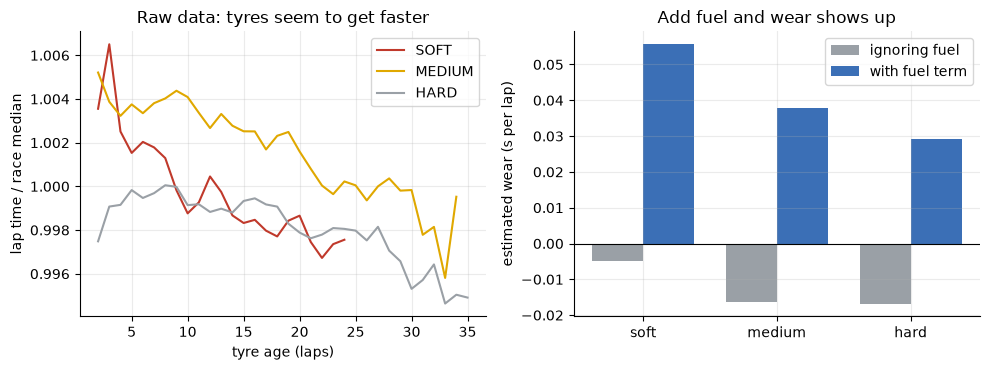

,ignoring fuel,with fuel
SOFT,-0.0049,0.0556
MEDIUM,-0.0164,0.0379
HARD,-0.0168,0.0291


In [2]:
c = clean_all[[(s, r) not in skip for s, r in zip(clean_all["season"], clean_all["round"])]].copy()
c = c[c["season"] <= 2024].copy()
c["race"] = c["season"].astype(str) + "-" + c["round"].astype(str)
c["tyre_age"] = c["tyre_age"].astype(float)
c["rel"] = c["lap_time_s"] / c.groupby("race")["lap_time_s"].transform("median")

def design(d, with_lap):
    X = pd.get_dummies(d[["race", "driver"]], drop_first=True).astype(float)
    if with_lap: X["lap_number"] = d["lap_number"]
    for comp in ("SOFT", "MEDIUM", "HARD"):
        X[f"age_{comp}"] = np.where(d["compound"] == comp, d["tyre_age"], 0.0)
        if comp != "HARD": X[f"offset_{comp}"] = (d["compound"] == comp).astype(float)
    return X
def wear(with_lap):
    X = design(c, with_lap); m = LinearRegression().fit(X, c["lap_time_s"])
    return pd.Series(m.coef_, X.columns)[["age_SOFT", "age_MEDIUM", "age_HARD"]].rename(lambda s: s[4:])
ignoring, with_fuel = wear(False), wear(True)

fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.8))
for comp, col in (("SOFT", RED), ("MEDIUM", "#e0a800"), ("HARD", GREY)):
    g = c[(c["compound"] == comp) & (c["tyre_age"] <= 35)].groupby("tyre_age")["rel"].agg(["median", "size"])
    g = g[g["size"] >= 50]; a.plot(g.index, g["median"], label=comp, color=col)
a.set_xlabel("tyre age (laps)"); a.set_ylabel("lap time / race median"); a.legend(); a.set_title("Raw data: tyres seem to get faster")
x = np.arange(3); w = 0.38
b.bar(x - w / 2, ignoring.values, w, color=GREY, label="ignoring fuel")
b.bar(x + w / 2, with_fuel.values, w, color=BLUE, label="with fuel term")
b.set_xticks(x, ["soft", "medium", "hard"]); b.axhline(0, color="k", lw=0.8); b.legend()
b.set_ylabel("estimated wear (s per lap)"); b.set_title("Add fuel and wear shows up")
save(fig, "fuel_hides_wear.png")
pd.DataFrame({"ignoring fuel": ignoring, "with fuel": with_fuel}).round(4)

## Safety car starts

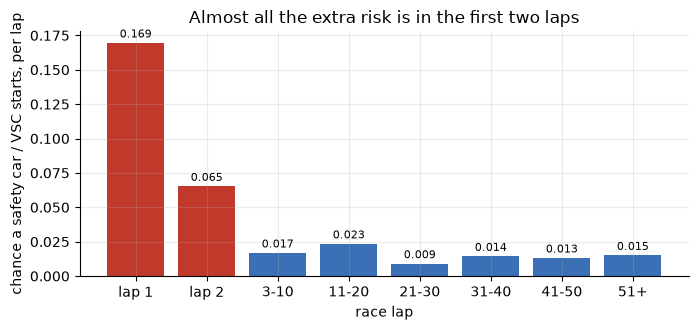

{'lap 1': np.float64(0.1695),
 'lap 2': np.float64(0.0652),
 '3-10': np.float64(0.0167),
 '11-20': np.float64(0.0234),
 '21-30': np.float64(0.009),
 '31-40': np.float64(0.0143),
 '41-50': np.float64(0.0131),
 '51+': np.float64(0.015)}

In [3]:
lap = lap_status(raw, skip); lap = lap[lap["season"] <= 2024]
table = hazard_table(lap)
edges = [(1, 1), (2, 2), (3, 10), (11, 20), (21, 30), (31, 40), (41, 50), (51, 80)]
labels = ["lap 1", "lap 2", "3-10", "11-20", "21-30", "31-40", "41-50", "51+"]
rates = [table[table["lap"].between(a_, b_)]["event"].mean() for a_, b_ in edges]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(labels, rates, color=[RED, RED] + [BLUE] * 6)
for i, r_ in enumerate(rates): ax.text(i, r_ + 0.004, f"{r_:.3f}", ha="center", fontsize=8)
ax.set_ylabel("chance a safety car / VSC starts, per lap"); ax.set_xlabel("race lap")
ax.set_title("Almost all the extra risk is in the first two laps")
save(fig, "safety_car_start_rate.png")
dict(zip(labels, np.round(rates, 4)))

## Safety car laps changed between seasons, because the data source did

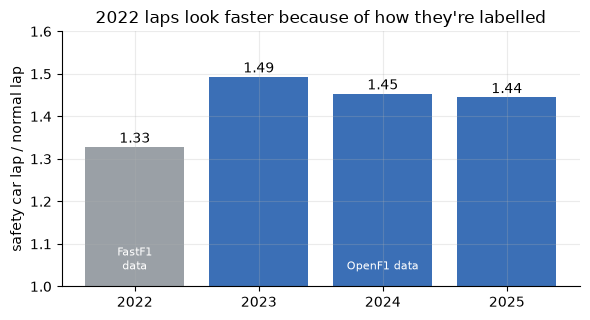

{2022: 1.328, 2023: 1.493, 2024: 1.453, 2025: 1.445}

In [4]:
pace = clean_all.groupby(["season", "round", "driver"])["lap_time_s"].median().rename("pace")
d = dry.join(pace, on=["season", "round", "driver"])
d = d[d["pace"].notna() & d["lap_time_s"].notna() & ~d["is_pit_in"] & ~d["is_pit_out"]]
d = d.assign(ratio=d["lap_time_s"] / d["pace"]).merge(lap_status(dry)[["season", "round", "lap_number", "rank"]], on=["season", "round", "lap_number"])
by = d[d["rank"] == 2].groupby("season")["ratio"].mean()
fig, ax = plt.subplots(figsize=(6, 3.3))
ax.bar([str(s) for s in by.index], by.values, color=[GREY, BLUE, BLUE, BLUE])
for i, v in enumerate(by.values): ax.text(i, v + 0.01, f"{v:.2f}", ha="center")
ax.set_ylim(1.0, 1.6); ax.set_ylabel("safety car lap / normal lap")
ax.text(0, 1.04, "FastF1\ndata", ha="center", fontsize=8, color="white"); ax.text(2, 1.04, "OpenF1 data", ha="center", fontsize=8, color="white")
ax.set_title("2022 laps look faster because of how they're labelled")
save(fig, "safety_car_pace_by_season.png")
by.round(3).to_dict()

## Model size by cross-validation

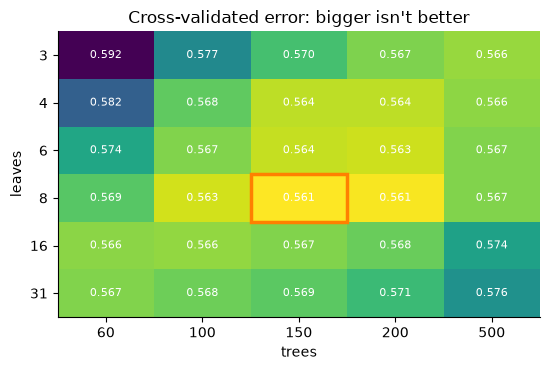

,60,100,150,200,500
3,0.592,0.577,0.570,0.567,0.566
4,0.582,0.568,0.564,0.564,0.566
6,0.574,0.567,0.564,0.563,0.567
8,0.569,0.563,0.561,0.561,0.567
16,0.566,0.566,0.567,0.568,0.574
31,0.567,0.568,0.569,0.571,0.576


In [5]:
train_dev, _ = split(prepare(raw, clean_all), "dev")
tracks = sorted(train_dev["track"].unique())
Xd, yd = gbm_features(train_dev, tracks), train_dev["delta_s"]
gd = (train_dev["season"].astype(str) + "-" + train_dev["round"].astype(str)).to_numpy()
leaves, trees = [3, 4, 6, 8, 16, 31], [60, 100, 150, 200, 500]
grid = pd.DataFrame(index=leaves, columns=trees, dtype=float)
for L in leaves:
    for T in trees:
        s = [mae(yd.iloc[te], pd.Series(make_gbm(L, T).fit(Xd.iloc[fi], yd.iloc[fi]).predict(Xd.iloc[te]), index=yd.index[te]))
             for fi, te in GroupKFold(5).split(Xd, yd, gd)]
        grid.loc[L, T] = np.mean(s)
fig, ax = plt.subplots(figsize=(5.6, 3.8))
im = ax.imshow(grid.values, cmap="viridis_r", aspect="auto")
ax.set_xticks(range(len(trees)), trees); ax.set_yticks(range(len(leaves)), leaves)
ax.set_xlabel("trees"); ax.set_ylabel("leaves"); ax.grid(False)
for i in range(len(leaves)):
    for j in range(len(trees)): ax.text(j, i, f"{grid.iloc[i, j]:.3f}", ha="center", va="center", color="white", fontsize=8)
i, j = np.unravel_index(grid.values.argmin(), grid.shape); ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False, ec=PAPAYA, lw=2.5))
ax.set_title("Cross-validated error: bigger isn't better")
save(fig, "gbm_size_cv.png")
grid.round(3)

## Do the intervals hold on a new season?

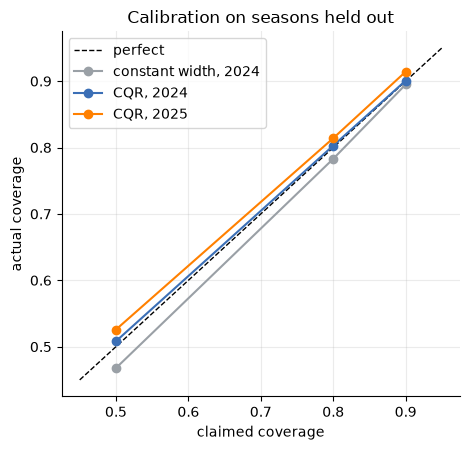

,constant 2024,CQR 2024,CQR 2025
0.5,0.468,0.508,0.526
0.8,0.783,0.803,0.814
0.9,0.895,0.901,0.914


In [6]:
dev, final = lap_time_results(raw, clean_all, "dev"), lap_time_results(raw, clean_all, "final")
Xtr, ytr = gbm_features(train_dev, tracks), train_dev["delta_s"]
_, test_dev = split(prepare(raw, clean_all), "dev")
Xte = gbm_features(test_dev, tracks)
const = {}
for level in (0.5, 0.8, 0.9):
    lo, hi = ConstantWidth(1 - level).fit(Xtr, ytr, gd).predict(Xte)
    const[level] = coverage(test_dev["delta_s"], lo, hi)
fig, ax = plt.subplots(figsize=(4.8, 4.6))
ax.plot([0.45, 0.95], [0.45, 0.95], "k--", lw=1, label="perfect")
ax.plot(list(const), list(const.values()), "o-", color=GREY, label="constant width, 2024")
ax.plot(dev["intervals"].index, dev["intervals"]["coverage"], "o-", color=BLUE, label="CQR, 2024")
ax.plot(final["intervals"].index, final["intervals"]["coverage"], "o-", color=PAPAYA, label="CQR, 2025")
ax.set_xlabel("claimed coverage"); ax.set_ylabel("actual coverage"); ax.legend(); ax.set_title("Calibration on seasons held out")
save(fig, "interval_calibration_both.png")
pd.DataFrame({"constant 2024": const, "CQR 2024": dev["intervals"]["coverage"], "CQR 2025": final["intervals"]["coverage"]}).round(3)

## What a pit stop costs

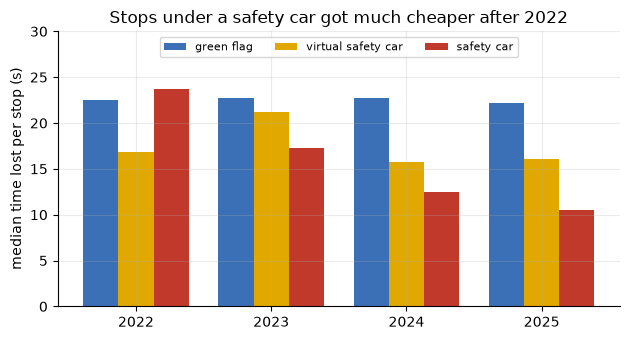

status,green,vsc,sc
season,,,
2022,22.5,16.8,23.7
2023,22.7,21.2,17.3
2024,22.8,15.7,12.5
2025,22.2,16.1,10.5


In [7]:
stops = pit_stops(dry)
med = stops.groupby(["season", "status"])["loss"].median().unstack("status")[["green", "vsc", "sc"]]   # raw medians, same as notebook 09
fig, ax = plt.subplots(figsize=(6.4, 3.5)); w = 0.26; x = np.arange(len(med))
for k, (col, lab, colr) in enumerate((("green", "green flag", BLUE), ("vsc", "virtual safety car", "#e0a800"), ("sc", "safety car", RED))):
    ax.bar(x + (k - 1) * w, med[col].values, w, label=lab, color=colr)
ax.set_xticks(x, med.index.astype(str)); ax.set_ylabel("median time lost per stop (s)"); ax.legend(ncol=3, fontsize=8, loc="upper center")
ax.set_ylim(0, 30); ax.set_title("Stops under a safety car got much cheaper after 2022")
save(fig, "pit_loss_by_season.png")
med.round(1)

## Where the simulator misses

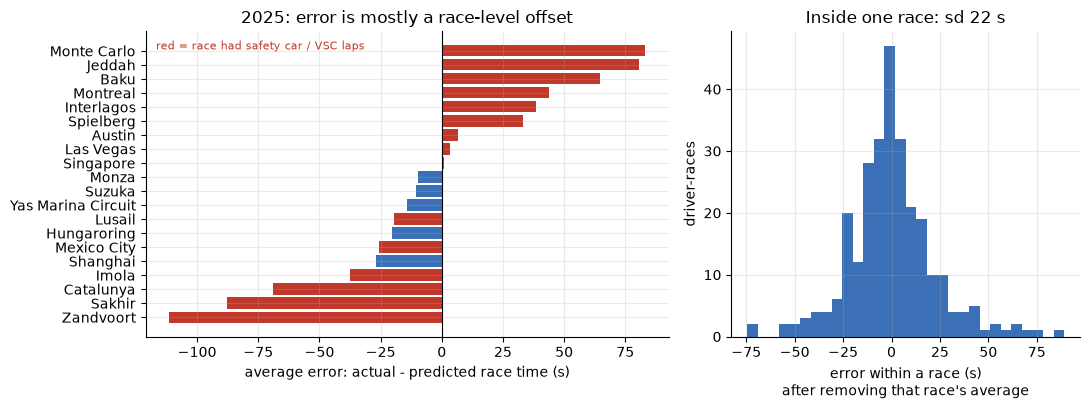

between-race sd 51.7 s, within-race sd 22.4 s


In [8]:
sm = simulator_results(raw, clean_all, "final")
rep = sm["replay"]
per = rep.groupby(["round", "track"]).agg(err=("error", "mean"), neutral=("neutral laps", "first"), n=("error", "size")).reset_index().sort_values("err")
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
a.barh(per["track"], per["err"], color=[RED if n > 0 else BLUE for n in per["neutral"]]); a.axvline(0, color="k", lw=0.8)
a.set_xlabel("average error: actual - predicted race time (s)"); a.set_title("2025: error is mostly a race-level offset")
a.text(0.02, 0.97, "red = race had safety car / VSC laps", transform=a.transAxes, fontsize=8, color=RED, va="top")
within = rep["error"] - rep.groupby("round")["error"].transform("mean")
b.hist(within, bins=30, color=BLUE); b.set_xlabel("error within a race (s)\nafter removing that race's average"); b.set_ylabel("driver-races")
b.set_title(f"Inside one race: sd {within.std():.0f} s")
save(fig, "simulator_race_level_error.png")
print(f"between-race sd {rep.groupby('round')['error'].mean().std():.1f} s, within-race sd {within.std():.1f} s")

## McLaren

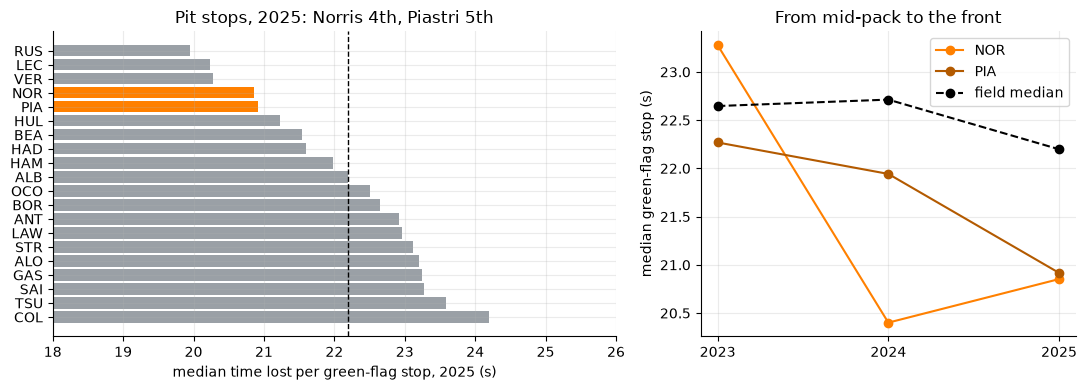

{2023: {'NOR': (23.28, 13), 'PIA': (22.27, 8)},
 2024: {'NOR': (20.4, 2), 'PIA': (21.94, 8)},
 2025: {'NOR': (20.85, 4), 'PIA': (20.92, 5)}}

In [9]:
g = stops[(stops["status"] == "green") & stops["loss"].between(10, 45)]
g25 = g[g["season"] == 2025].groupby("driver")["loss"].agg(["median", "size"]); g25 = g25[g25["size"] >= 12].sort_values("median")
by_season = {s: g[g["season"] == s] for s in (2023, 2024, 2025)}
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.5, 1]})
a.barh(g25.index, g25["median"], color=[PAPAYA if d in MCLAREN else GREY for d in g25.index]); a.invert_yaxis()
a.axvline(g[g["season"] == 2025]["loss"].median(), color="k", ls="--", lw=1); a.set_xlim(18, 26)
a.set_xlabel("median time lost per green-flag stop, 2025 (s)"); a.set_title("Pit stops, 2025: Norris 4th, Piastri 5th")
for d, col in (("NOR", PAPAYA), ("PIA", "#b35a00")):
    b.plot([2023, 2024, 2025], [by_season[s][by_season[s]["driver"] == d]["loss"].median() for s in by_season], "o-", color=col, label=d)
b.plot([2023, 2024, 2025], [by_season[s]["loss"].median() for s in by_season], "o--", color="k", label="field median")
b.set_xticks([2023, 2024, 2025]); b.legend(); b.set_ylabel("median green-flag stop (s)"); b.set_title("From mid-pack to the front")
save(fig, "mclaren_pit_stops.png")
ranks = {s: g[g["season"] == s].groupby("driver")["loss"].agg(["median", "size"]).query("size >= 12")["median"].rank() for s in by_season}
{s: {d: (round(float(g[(g['season']==s)&(g['driver']==d)]['loss'].median()), 2), int(r[d])) for d in MCLAREN} for s, r in ranks.items()}

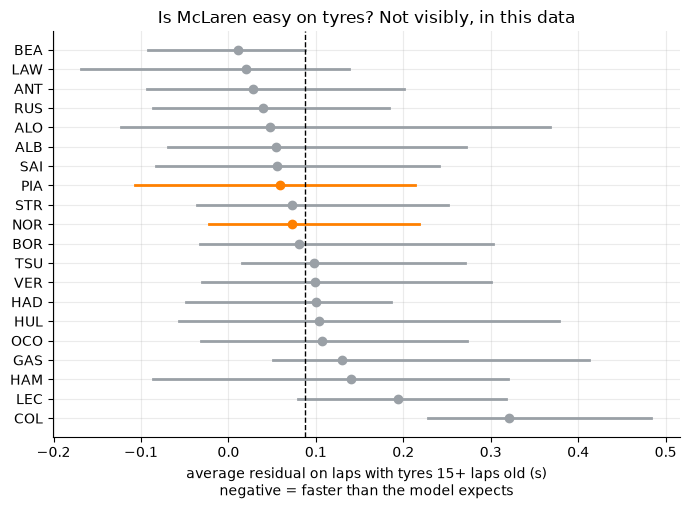

,mean,lo,hi,rank
driver,,,,
NOR,0.073,-0.022,0.219,10
PIA,0.059,-0.107,0.214,8


In [10]:
train_f, test_f = split(prepare(raw, clean_all), "final"); tracks_f = sorted(train_f["track"].unique())
model = make_gbm(GBM_LEAVES, GBM_TREES, 0).fit(gbm_features(train_f, tracks_f), train_f["delta_s"])
test_f = test_f.assign(res=test_f["delta_s"] - model.predict(gbm_features(test_f, tracks_f)))
old = test_f[test_f["tyre_age"] >= 15]
per_dr = old.groupby(["driver", "round"])["res"].mean().reset_index()
rng = np.random.default_rng(0); rows = []
for d, grp in per_dr.groupby("driver"):
    if old[old["driver"] == d].shape[0] < 150: continue
    v = grp["res"].to_numpy(); boots = [rng.choice(v, len(v)).mean() for _ in range(2000)]
    rows.append((d, old[old["driver"] == d]["res"].mean(), np.quantile(boots, .05), np.quantile(boots, .95)))
t = pd.DataFrame(rows, columns=["driver", "mean", "lo", "hi"]).sort_values("mean").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7, 5.2))
for i, r_ in t.iterrows():
    col = PAPAYA if r_["driver"] in MCLAREN else GREY
    ax.plot([r_["lo"], r_["hi"]], [i, i], color=col, lw=2); ax.plot(r_["mean"], i, "o", color=col)
ax.set_yticks(range(len(t)), t["driver"]); ax.invert_yaxis(); ax.axvline(old["res"].mean(), color="k", ls="--", lw=1)
ax.set_xlabel("average residual on laps with tyres 15+ laps old (s)\nnegative = faster than the model expects")
ax.set_title("Is McLaren easy on tyres? Not visibly, in this data")
save(fig, "mclaren_tyre_proxy.png")
t.set_index("driver").loc[MCLAREN].round(3).assign(rank=[int(t.index[t["driver"] == d][0]) + 1 for d in MCLAREN])

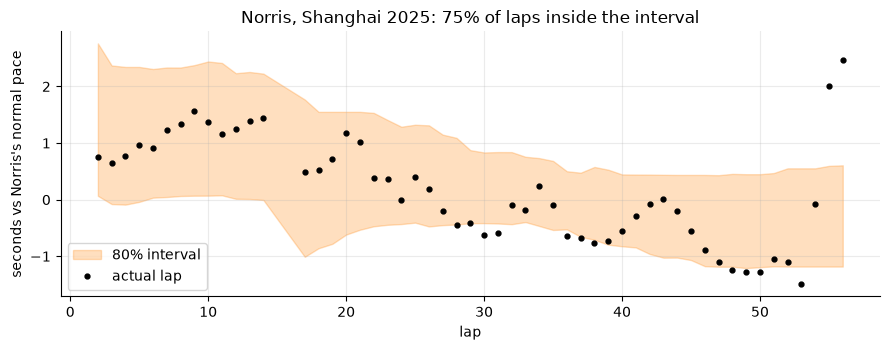

race round 2, 53 laps, 75% inside the 80% interval


In [11]:
groups_f = (train_f["season"].astype(str) + "-" + train_f["round"].astype(str)).to_numpy()
cqr = CQR(0.2).fit(gbm_features(train_f, tracks_f), train_f["delta_s"], groups_f)
lo, hi = cqr.predict(gbm_features(test_f, tracks_f))
test_f = test_f.assign(lo=lo, hi=hi)
nor = test_f[test_f["driver"] == "NOR"]
rnd = min(r_ for r_, g_ in nor.groupby("round") if len(g_) >= 40)   # first 2025 race, in calendar order, with enough laps
one = nor[nor["round"] == rnd].sort_values("lap_number")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.fill_between(one["lap_number"], one["lo"], one["hi"], color=PAPAYA, alpha=0.25, label="80% interval")
ax.plot(one["lap_number"], one["delta_s"], "o", ms=3.5, color="k", label="actual lap")
inside = ((one["delta_s"] >= one["lo"]) & (one["delta_s"] <= one["hi"])).mean()
ax.set_xlabel("lap"); ax.set_ylabel("seconds vs Norris's normal pace"); ax.legend()
ax.set_title(f"Norris, {one['track'].iloc[0]} 2025: {inside:.0%} of laps inside the interval")
save(fig, "norris_interval_example.png")
print(f"race round {rnd}, {len(one)} laps, {inside:.0%} inside the 80% interval")

In [12]:
# a few numbers the README quotes
sim_final = build_simulator(raw, clean_all, seasons=(2022, 2023, 2024))
print(f"noise pools (final build): stint-level sd {sim_final.pools['stint_shift'].std():.3f} s, lap-level sd {sim_final.pools['lap_noise'].std():.3f} s")
res = rep.assign(mc=rep["driver"].isin(MCLAREN))
print(res.groupby("mc").agg(driver_races=("error", "size"), median_abs_error=("error", lambda s: s.abs().median()), inside_80=("inside", "mean")).round(2))

noise pools (final build): stint-level sd 0.494 s, lap-level sd 0.974 s
       driver_races  median_abs_error  inside_80
mc                                              
False           239             33.36       0.64
True             37             22.23       0.78
